# Optativa III: Ciencia de Datos
## Minería de datos y aprendizaje no supervisado — Guía paso a paso

**Universidad de Especialidades UNE · Plantel Centro**
**Ingeniería en Computación · 9.º semestre**

---

### ¿Qué vas a aprender?

Hasta ahora, cuando entrenabas un modelo, tenías una "respuesta correcta" que querías predecir (el ingreso, el precio). Eso es **aprendizaje supervisado**. Pero muchas veces NO hay respuesta correcta: solo tienes datos y quieres **descubrir patrones ocultos** en ellos. Eso es el **aprendizaje no supervisado**, y es el corazón de la minería de datos.

En esta guía aprenderás, paso a paso y con ejemplos sencillos:

1. **Clustering (agrupamiento):** descubrir grupos naturales en los datos sin decirle al programa cuáles son.
   - K-means, clustering jerárquico y DBSCAN.
   - Cómo saber cuántos grupos hay (método del codo y silueta).
2. **Reglas de asociación:** descubrir qué cosas van juntas (el famoso "quien compra X también compra Y").
3. **PCA:** resumir muchas variables en pocas para poder visualizar los datos.

### La idea central, en una frase

> **Aprendizaje supervisado** = "enséñame a predecir una respuesta que ya conozco."
> **Aprendizaje no supervisado** = "muéstrame los patrones que yo no sabía que estaban ahí."

### Cómo trabajar (en Visual Studio Code)

1. Abre VS Code y crea una carpeta para esta actividad.
2. Crea un entorno virtual e instala las librerías (ver Paso 0).
3. Sube los archivos `clientes.csv` y `transacciones.csv` a tu carpeta.
4. Ejecuta cada celda en orden, lee las explicaciones y responde las preguntas.

> **Consejo:** no corras hacia adelante. Cada paso construye sobre el anterior. Lee las analogías: están pensadas para que entiendas la idea antes de ver el código.


---
# PARTE 1 — Clustering: encontrar grupos naturales

## La idea con una analogía

Imagina que entras a una fiesta y, sin que nadie te diga nada, notas que la gente se ha agrupado sola: unos jóvenes bailando, unos adultos conversando en un sofá, unos niños jugando. Nadie los organizó; se agruparon por afinidad. **Eso es clustering:** el algoritmo encuentra grupos naturales en los datos, sin que tú le digas cuáles son.

Lo usaremos para **segmentar clientes**: descubrir qué tipos de clientes tiene una tienda, para tratarlos distinto.

## Paso 0 — Preparación


In [1]:
# En la terminal de VS Code, con tu entorno virtual activado, instala:
#   pip install pandas scikit-learn matplotlib scipy mlxtend
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

clientes = pd.read_csv("clientes.csv")
print("Clientes:", clientes.shape)
clientes.head()

Clientes: (600, 4)


,cliente_id,edad,ingreso_mensual,puntaje_gasto
0,1,41,21564,28
1,2,37,112324,68
2,3,61,37311,18
3,4,54,41990,39
4,5,25,18539,36


> ✍️ **1.** ¿Cuántos clientes hay y qué sabemos de cada uno (qué columnas)? La variable `puntaje_gasto` va de 1 a 100 e indica cuánto gasta un cliente. ¿Qué tipo de información tenemos: hay alguna "respuesta correcta" que queramos predecir, o solo características de los clientes?

> ✍️ **2.** Como NO hay una variable objetivo (no estamos prediciendo nada), esto es aprendizaje **no supervisado**. Con tus palabras: ¿qué crees que podríamos "descubrir" sobre estos clientes sin predecir nada?


**Respuesta 1.** Hay **600 clientes** y 4 columnas: `cliente_id` (identificador), `edad`, `ingreso_mensual` y `puntaje_gasto` (1–100). No hay ninguna "respuesta correcta" que predecir: solo tenemos **características** de cada cliente. El `cliente_id` ni siquiera es una característica, solo una etiqueta.

**Respuesta 2.** Podríamos descubrir **tipos de clientes** que se parecen entre sí: por ejemplo, jóvenes de ingreso bajo que gastan mucho, adultos de ingreso alto que también gastan mucho, o personas mayores que gastan poco. Con esos grupos la tienda puede diseñar campañas distintas para cada uno sin haber definido los grupos de antemano.

## Paso 1 — Preparar los datos: la importancia de la escala

Antes de agrupar, un detalle crucial. El ingreso está en miles (15000) y la edad en decenas (40). Si no los ponemos en la misma escala, el ingreso **dominaría** todo el cálculo solo por tener números más grandes. Por eso **estandarizamos** (como viste en la Semana 4).


In [2]:
# Usamos solo las características para agrupar (no el id)
X = clientes[["edad", "ingreso_mensual", "puntaje_gasto"]]

# Estandarizar: poner todas las variables en la misma escala
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X)

print("Antes de escalar (primeras filas):")
print(X.head(2).to_string(index=False))
print("\nDespués de escalar (media 0, desviación 1):")
print(pd.DataFrame(X_escalado, columns=X.columns).head(2).round(2).to_string(index=False))

Antes de escalar (primeras filas):
 edad  ingreso_mensual  puntaje_gasto
   41            21564             28
   37           112324             68

Después de escalar (media 0, desviación 1):
 edad  ingreso_mensual  puntaje_gasto
 -0.1            -0.70          -1.10
 -0.4             3.22           0.75


> ✍️ **3.** ¿Por qué si NO estandarizáramos, el `ingreso_mensual` (con números de miles) dominaría el agrupamiento frente a la `edad` (con números de decenas)? Piensa en qué significa "distancia" entre dos clientes.


**Respuesta 3.** K-means agrupa por **distancia euclidiana**. Si dos clientes difieren 20 años de edad pero 20,000 de ingreso, la diferencia de ingreso pesa 1,000 veces más en la distancia, así que el algoritmo prácticamente solo "vería" el ingreso y la edad y el gasto no influirían. Al estandarizar (media 0, desviación 1) las tres variables pesan lo mismo: en la salida, el cliente 2 tiene ingreso escalado 3.22 (muy por encima del promedio) y gasto 0.75, valores ya comparables entre sí.

## Paso 2 — K-means: el método más popular

**La idea con una analogía:** imagina que quieres dividir a los clientes en 3 grupos. K-means hace esto:
1. Pone 3 "banderas" al azar en el espacio de datos (los **centroides**).
2. Cada cliente se une a la bandera más cercana.
3. Cada bandera se mueve al centro de su grupo.
4. Repite hasta que las banderas dejan de moverse.

El resultado: 3 grupos donde los clientes de cada uno se parecen entre sí.


In [3]:
from sklearn.cluster import KMeans

# Probamos con 4 grupos (luego veremos cómo elegir el número)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clientes["grupo"] = kmeans.fit_predict(X_escalado)

print("Número de clientes en cada grupo:")
print(clientes["grupo"].value_counts().sort_index())

Número de clientes en cada grupo:
grupo
0    185
1    173
2    102
3    140
Name: count, dtype: int64


> ✍️ **4.** ¿Cuántos clientes quedaron en cada uno de los 4 grupos? ¿Están equilibrados o hay grupos mucho más grandes que otros?


**Respuesta 4.** Grupo 0: **185**, grupo 1: **173**, grupo 2: **102** y grupo 3: **140** clientes. Están razonablemente equilibrados; el más pequeño es el grupo 2 (17% de los clientes) y el más grande el grupo 0 (31%). Ningún grupo es diminuto ni absorbe a casi todos.

## Paso 3 — ¿Cuántos grupos elegir? El método del codo

Pusimos 4 grupos, pero ¿y si el número correcto era 3 o 5? El **método del codo** nos ayuda a decidir. Mide qué tan "apretados" están los grupos (la **inercia**) para distintos números de grupos. Buscamos el punto donde la curva forma un "codo": agregar más grupos ya no mejora mucho.


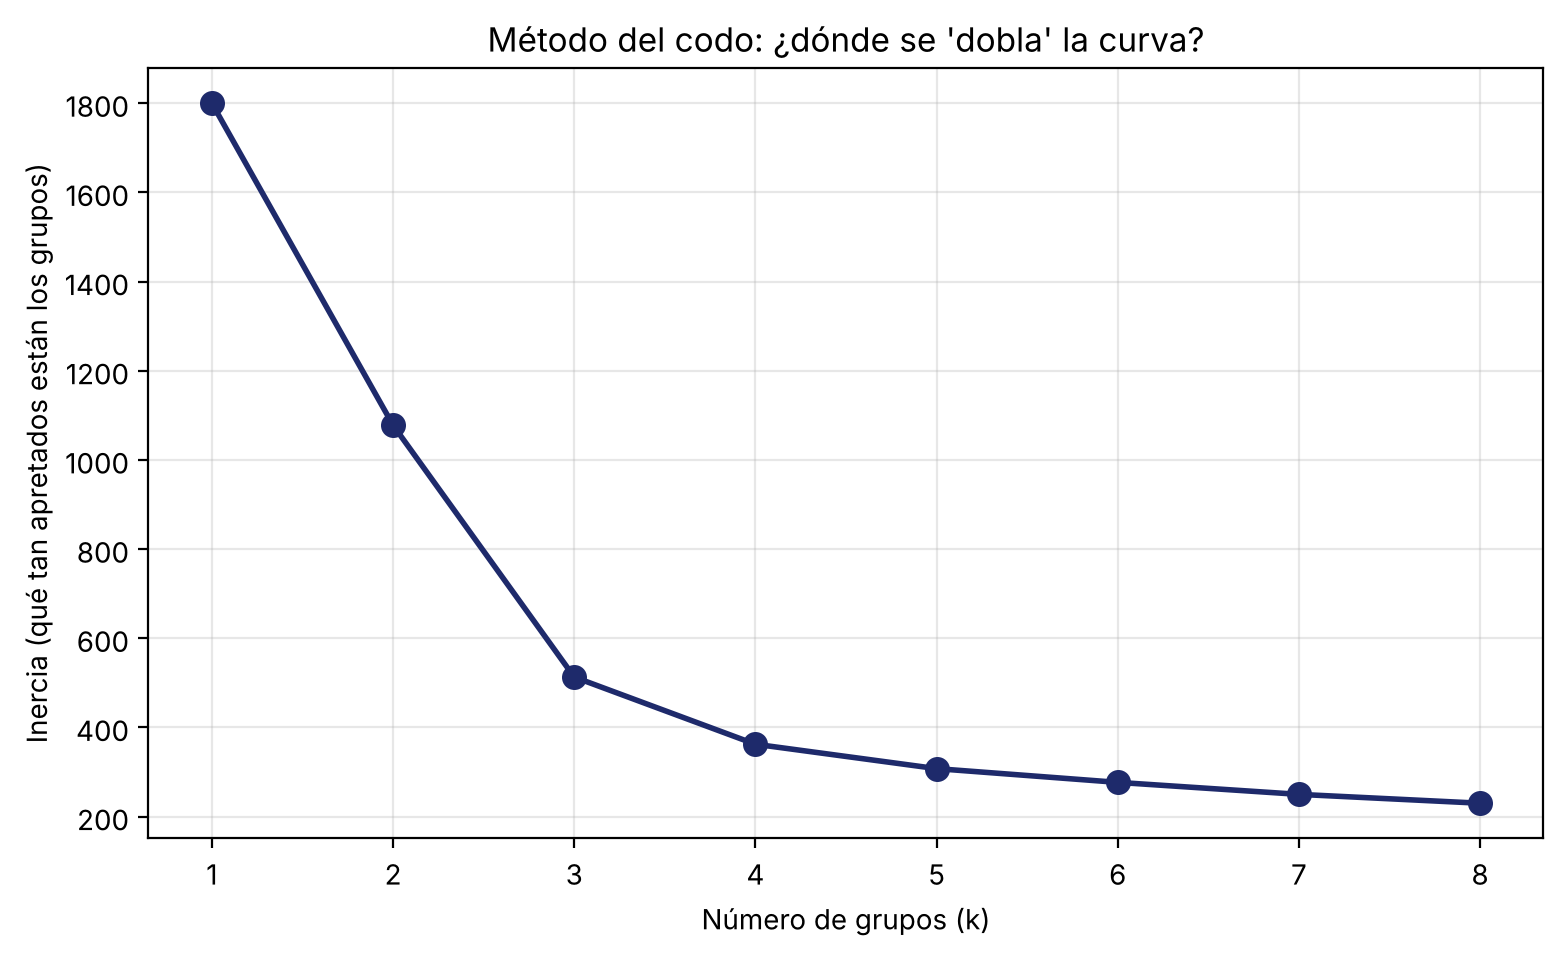

k=1: inercia=1800
k=2: inercia=1078
k=3: inercia=513
k=4: inercia=362
k=5: inercia=308
k=6: inercia=277
k=7: inercia=250
k=8: inercia=230


In [4]:
# Calculamos la inercia para distintos números de grupos (de 1 a 8)
inercias = []
for k in range(1, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_escalado)
    inercias.append(km.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(range(1, 9), inercias, "o-", color="#1e2a6b", linewidth=2, markersize=8)
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inercia (qué tan apretados están los grupos)")
plt.title("Método del codo: ¿dónde se 'dobla' la curva?")
plt.grid(alpha=0.3)
plt.show()

for k, iner in zip(range(1, 9), inercias):
    print(f"k={k}: inercia={iner:.0f}")

> ✍️ **5.** Mira la gráfica. ¿En qué número de grupos (k) la curva deja de bajar bruscamente y empieza a aplanarse? Ese "codo" sugiere el número ideal de grupos. ¿Cuál dirías que es?

> ✍️ **6.** La inercia SIEMPRE baja al agregar más grupos (con k = número de clientes, la inercia sería 0). Por eso NO elegimos simplemente el k con menor inercia. Explica con tus palabras por qué el "codo" es mejor criterio que "el valor más bajo".


**Respuesta 5.** La inercia baja así: k=1 → 1800, k=2 → 1078, k=3 → 513, k=4 → 362, k=5 → 308, k=6 → 277. Las caídas grandes ocurren hasta k=3 (−565) y todavía k=4 aporta una mejora apreciable (−151); a partir de k=4 la curva se aplana (−54, −31, −27…). El codo está entre **3 y 4**; yo elijo **k = 4**, porque después de 4 agregar grupos casi no mejora.

**Respuesta 6.** Porque la inercia siempre disminuye al agregar grupos: con un grupo por cliente sería 0, pero eso no dice nada útil (cada cliente sería su propio "segmento"). El codo busca el **equilibrio**: el punto donde agregar un grupo más deja de explicar estructura real y empieza a partir grupos que ya eran naturales. Así obtenemos pocos grupos, compactos e interpretables.

## Paso 4 — La silueta: otra forma de evaluar

El **coeficiente de silueta** mide qué tan bien separados están los grupos, en una escala de −1 a 1 (más alto es mejor). Nos da una segunda opinión sobre cuántos grupos usar.


In [5]:
from sklearn.metrics import silhouette_score

print("Coeficiente de silueta para distintos números de grupos:")
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_escalado)
    sil = silhouette_score(X_escalado, etiquetas)
    print(f"  k={k}: silueta={sil:.3f}")

Coeficiente de silueta para distintos números de grupos:
  k=2: silueta=0.385
  k=3: silueta=0.520


  k=4: silueta=0.466
  k=5: silueta=0.419
  k=6: silueta=0.375
  k=7: silueta=0.339


> ✍️ **7.** ¿Qué número de grupos tiene la silueta más alta? ¿Coincide (más o menos) con lo que sugería el método del codo? Cuando dos métodos distintos apuntan a un número parecido, tienes más confianza en tu elección.


**Respuesta 7.** La silueta más alta es **k = 3 (0.520)**, seguida de k = 4 (0.466); de ahí baja (0.419, 0.375, 0.339). Coincide más o menos con el codo, que señalaba la zona 3–4. Me quedo con **k = 4** porque su silueta sigue siendo buena (>0.45), el codo apunta a 4 y, como se ve en el perfil, separa a los adultos de ingreso medio (grupo 3) de los mayores de gasto bajo (grupo 1), que con k = 3 quedarían juntos y darían un segmento menos útil.

## Paso 5 — Interpretar los grupos: la parte más importante

Agrupar es fácil; lo valioso es **entender qué significa cada grupo**. Vamos a describir cada grupo por sus características promedio y darle un nombre de negocio.


In [6]:
# Reagrupamos con el número de grupos que elegimos (ajusta k según tu análisis)
k_elegido = 4
kmeans = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
clientes["grupo"] = kmeans.fit_predict(X_escalado)

# Perfil de cada grupo: promedio de cada característica
perfil = clientes.groupby("grupo")[["edad", "ingreso_mensual", "puntaje_gasto"]].mean().round(0)
perfil["num_clientes"] = clientes["grupo"].value_counts().sort_index()
print("Perfil de cada grupo:")
print(perfil)

Perfil de cada grupo:
       edad  ingreso_mensual  puntaje_gasto  num_clientes
grupo                                                    
0      28.0          15258.0           59.0           185
1      60.0          31465.0           31.0           173
2      37.0          79134.0           83.0           102
3      44.0          45022.0           45.0           140


> ✍️ **8.** Mira el perfil de cada grupo. Para CADA grupo, descríbelo en una frase y ponle un nombre de negocio. Por ejemplo: "Grupo 0: jóvenes de bajo ingreso pero que gastan mucho → 'Jóvenes impulsivos'". Hazlo para los 4 grupos.

> ✍️ **9.** Si fueras el gerente de la tienda, ¿a qué grupo le enviarías promociones de productos caros y por qué? Esta es la utilidad real del clustering: tratar distinto a cada segmento.


**Respuesta 8.** Perfil obtenido (promedios):

| Grupo | Edad | Ingreso | Gasto | Clientes | Descripción | Nombre |
|---|---|---|---|---|---|---|
| 0 | 28 | 15,258 | 59 | 185 | Jóvenes de ingreso bajo que gastan por encima de lo que ganarían | **"Jóvenes gastadores"** |
| 1 | 60 | 31,465 | 31 | 173 | Mayores con ingreso medio-bajo y el gasto más bajo | **"Mayores ahorradores"** |
| 2 | 37 | 79,134 | 83 | 102 | Adultos de alto ingreso y alto gasto | **"Premium / VIP"** |
| 3 | 44 | 45,022 | 45 | 140 | Adultos de ingreso medio y gasto moderado | **"Clase media prudente"** |

**Respuesta 9.** Al **grupo 2 ("Premium")**: tiene el ingreso más alto (≈79 mil) y el puntaje de gasto más alto (83), así que tiene capacidad y disposición para comprar productos caros. Al grupo 0 le enviaría promociones de productos de moda a precio accesible (gastan mucho pero ganan poco) y al grupo 1 ofertas de valor/descuento.

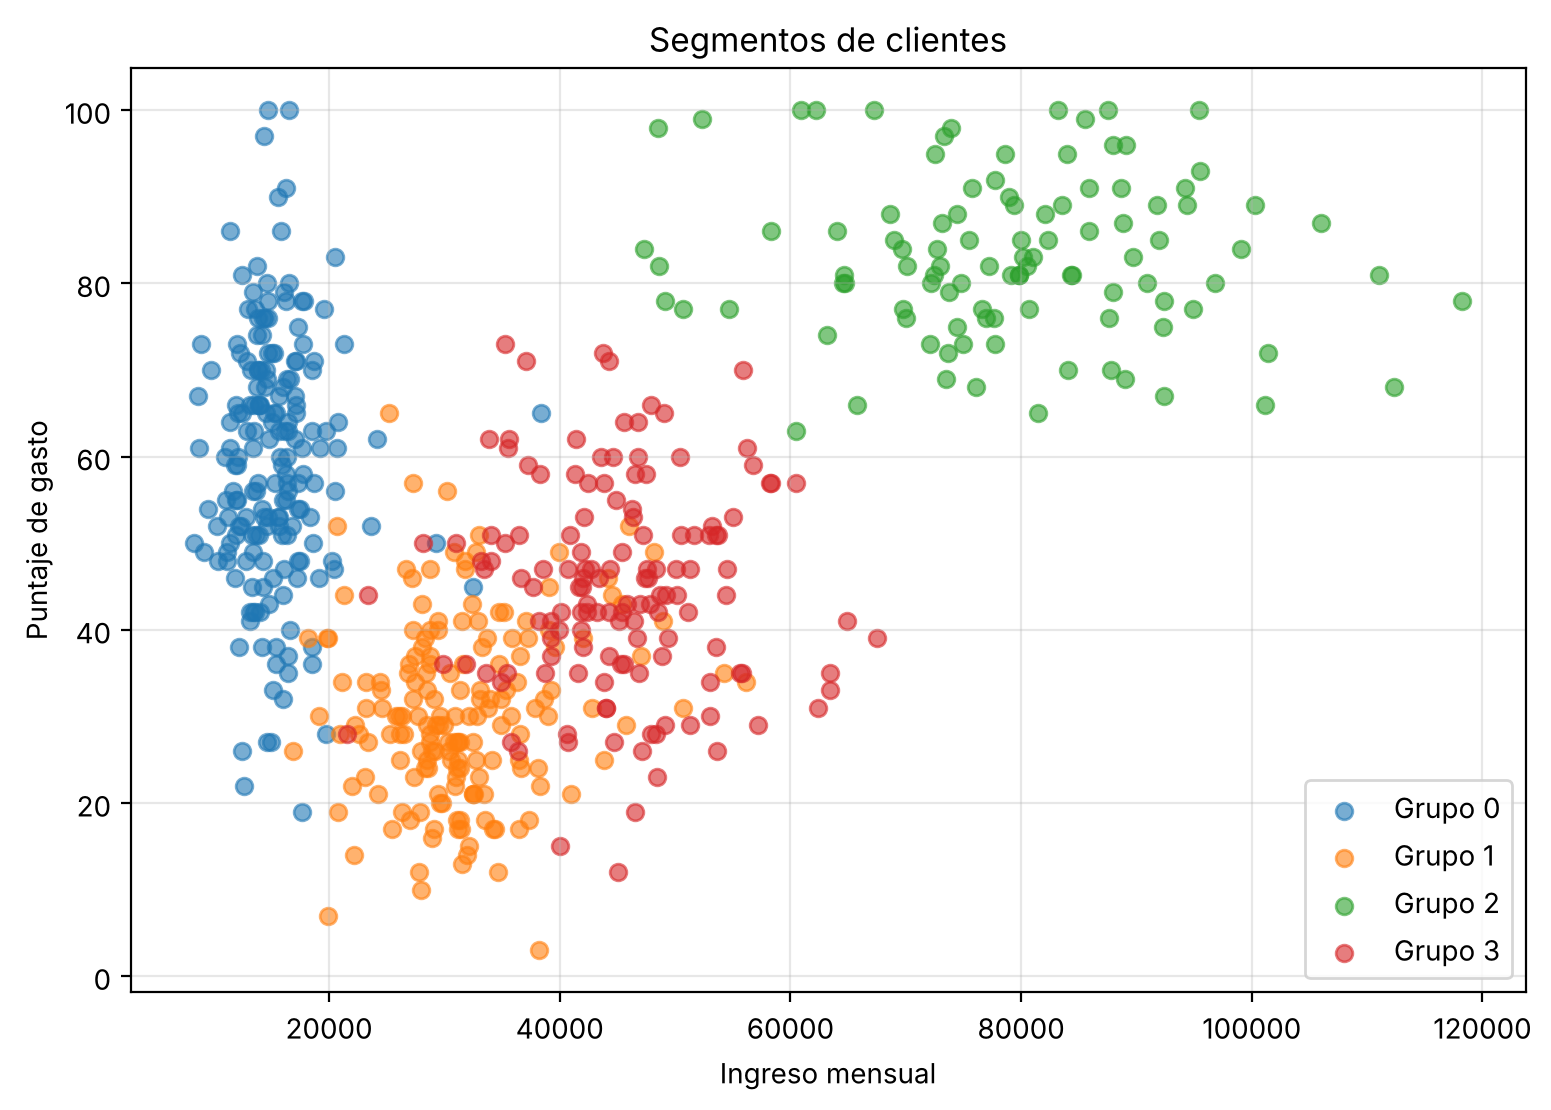

In [7]:
# Visualizamos los grupos (ingreso vs gasto, coloreado por grupo)
plt.figure(figsize=(9, 6))
for g in sorted(clientes["grupo"].unique()):
    sub = clientes[clientes["grupo"] == g]
    plt.scatter(sub["ingreso_mensual"], sub["puntaje_gasto"], label=f"Grupo {g}", alpha=0.6)
plt.xlabel("Ingreso mensual"); plt.ylabel("Puntaje de gasto")
plt.title("Segmentos de clientes")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

> ✍️ **10.** En la gráfica, ¿los grupos se ven bien separados o se mezclan? ¿Qué par de variables (de las que graficaste) parece separar mejor a los clientes?


**Respuesta 10.** En ingreso vs gasto, el **grupo 2 (verde) y el grupo 0 (azul) se ven muy separados**: el verde arriba a la derecha (ingreso alto y gasto alto) y el azul en una franja de ingreso bajo (~10–20 mil). En cambio, los **grupos 1 y 3 se mezclan** en la zona de ingreso 25–55 mil y gasto 20–60; lo que los separa realmente es la **edad** (60 vs 44 años), que no aparece en esta gráfica. El ingreso es la variable que más separa en este par; el gasto ayuda a distinguir al grupo premium.

### 🔧 Reto 1 — Clustering jerárquico

Existe otra forma de agrupar: el **clustering jerárquico**, que construye un árbol de grupos (como un árbol genealógico). Pruébalo y compara su silueta con la de K-means.


In [8]:
# RETO 1: clustering jerárquico
from sklearn.cluster import AgglomerativeClustering
jerarquico = AgglomerativeClustering(n_clusters=4)
etiquetas_j = jerarquico.fit_predict(X_escalado)
print("Silueta jerárquico:", round(silhouette_score(X_escalado, etiquetas_j), 3))
print("Silueta K-means (k=4):", round(silhouette_score(X_escalado, clientes["grupo"]), 3))
print("Tamaños jerárquico:", pd.Series(etiquetas_j).value_counts().sort_index().tolist())

Silueta jerárquico: 0.454
Silueta K-means (k=4): 0.466
Tamaños jerárquico: [181, 133, 183, 103]


> ✍️ **11.** ¿El clustering jerárquico dio una silueta parecida a la de K-means? ¿Cuándo preferirías el jerárquico? (Pista: cuando quieres ver la jerarquía de grupos en un dendrograma, o cuando no sabes cuántos grupos hay.)


**Respuesta 11.** Sí: el jerárquico dio silueta **0.454** contra **0.466** de K-means con k = 4, prácticamente iguales, y tamaños parecidos (181, 133, 183, 103 vs 185, 173, 102, 140). Preferiría el jerárquico cuando quiero ver **cómo se van uniendo los grupos** en un dendrograma (por ejemplo, para decidir el número de grupos cortando el árbol), cuando no sé cuántos grupos hay o cuando el dataset es pequeño, porque su costo crece mucho con el número de datos.

### 🔧 Reto 2 — DBSCAN: agrupar por densidad

**DBSCAN** agrupa de otra forma: junta puntos que están muy juntos (densos) y marca como "ruido" los puntos aislados. A diferencia de K-means, NO hay que decirle cuántos grupos; él los descubre. Y detecta valores atípicos.


In [9]:
# RETO 2: DBSCAN
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.6, min_samples=10)
etiquetas_db = dbscan.fit_predict(X_escalado)
n_grupos = len(set(etiquetas_db)) - (1 if -1 in etiquetas_db else 0)
n_ruido = list(etiquetas_db).count(-1)
print(f"DBSCAN encontró {n_grupos} grupos y marcó {n_ruido} clientes como ruido (atípicos)")
print("Tamaños por etiqueta (-1 = ruido):", pd.Series(etiquetas_db).value_counts().sort_index().to_dict())

DBSCAN encontró 2 grupos y marcó 20 clientes como ruido (atípicos)
Tamaños por etiqueta (-1 = ruido): {-1: 20, 0: 492, 1: 88}


> ✍️ **12.** ¿Cuántos grupos encontró DBSCAN por sí solo y cuántos clientes marcó como "ruido"? ¿Qué ventaja tiene DBSCAN sobre K-means? (Pista: no hay que decirle el número de grupos y detecta atípicos.)

> ✍️ **13.** Compara las tres técnicas de clustering que usaste (K-means, jerárquico, DBSCAN). Haz una pequeña tabla mental: ¿cuál requiere decir el número de grupos de antemano? ¿Cuál detecta ruido? ¿Cuál fue más fácil de interpretar en este caso?


**Respuesta 12.** DBSCAN encontró **2 grupos** (de 492 y 88 clientes) y marcó **20 clientes como ruido**. Al cruzarlo con K-means, el grupo de 88 son clientes del segmento Premium (grupo 2), que es la nube más separada; los otros tres segmentos de K-means quedaron casi completos en el grupo de 492, porque están tan pegados entre sí que, con `eps=0.6`, DBSCAN los une en uno solo. 12 de los 20 atípicos pertenecen al grupo Premium, el más disperso. Sus ventajas: **no hay que decirle cuántos grupos** y **detecta atípicos** (esos 20 clientes raros que K-means mete a la fuerza en algún grupo).

**Respuesta 13.**

| Técnica | ¿Requiere k de antemano? | ¿Detecta ruido? | Resultado aquí |
|---|---|---|---|
| K-means | Sí | No | 4 grupos, silueta 0.466 — **el más fácil de interpretar** |
| Jerárquico | Sí (o cortar el dendrograma) | No | 4 grupos, silueta 0.454, casi igual |
| DBSCAN | No (pide `eps` y `min_samples`) | **Sí** (20 atípicos) | Solo 2 grupos; útil para atípicos, menos para segmentar |

En este caso K-means fue el más interpretable porque los grupos tienen forma más o menos redonda y tamaño parecido, que es justo lo que K-means supone.

---
# PARTE 2 — Reglas de asociación: ¿qué productos van juntos?

## La idea con una analogía

¿Has notado que en el súper los pañales a veces están cerca de la cerveza? No es casualidad: un análisis famoso descubrió que muchos papás jóvenes, al ir por pañales, también compraban cerveza. Eso es una **regla de asociación**: "si compra pañales, probablemente compra cerveza". Las tiendas usan esto para acomodar productos y hacer recomendaciones ("quien compró esto también compró...").

Lo descubriremos con el algoritmo **Apriori** sobre datos de transacciones (el "análisis de canasta de mercado").


In [10]:
# Cargamos las transacciones (cada fila es una compra con varios productos)
trans_df = pd.read_csv("transacciones.csv")
print("Número de transacciones:", len(trans_df))
print("\nEjemplos de compras:")
for i in range(5):
    print(" -", trans_df["items"].iloc[i])

# Convertimos el texto "pan,leche,huevos" en listas
transacciones = [fila.split(",") for fila in trans_df["items"]]

Número de transacciones: 1322

Ejemplos de compras:
 - mantequilla,pan
 - azucar,cafe,galletas,mantequilla,pan
 - huevos,leche
 - cerveza,mantequilla,pan,pañales
 - azucar,cafe


> ✍️ **14.** Mira los ejemplos de compras. Cada transacción es una "canasta" con varios productos. ¿Qué crees que podríamos descubrir analizando miles de estas canastas juntas?


**Respuesta 14.** Las canastas tienen 2 a 10 productos y se repiten combinaciones como "mantequilla + pan", "azúcar + café" o "cerveza + papas/pañales". Analizando las 1,322 canastas juntas podríamos descubrir **qué productos se compran juntos con más frecuencia de lo que dictaría el azar**, y convertirlo en reglas del tipo "si compra X, también compra Y", útiles para acomodo de anaqueles, promociones en paquete y recomendaciones.

## Paso 6 — Preparar los datos para Apriori

Apriori necesita los datos en una tabla donde cada fila es una compra y cada columna un producto, marcado con Verdadero/Falso según si estaba o no en la canasta.


In [11]:
from mlxtend.preprocessing import TransactionEncoder

codificador = TransactionEncoder()
matriz = codificador.fit(transacciones).transform(transacciones)
canastas = pd.DataFrame(matriz, columns=codificador.columns_)

print("Tabla de canastas (True = el producto estaba en la compra):")
print(canastas.head(3))

Tabla de canastas (True = el producto estaba en la compra):
   azucar   cafe  cerveza  galletas  huevos  leche  mantequilla    pan  papas  \
0   False  False    False     False   False  False         True   True  False   
1    True   True    False      True   False  False         True   True  False   
2   False  False    False     False    True   True        False  False  False   

   pañales  queso  refresco  
0    False  False     False  
1    False  False     False  
2    False  False     False  


> ✍️ **15.** Esta tabla tiene una fila por compra y una columna por producto. Si tuvieras 10,000 productos distintos, ¿cuántas columnas tendría? ¿Por qué estos datos son "dispersos" (la mayoría de celdas son False)?


**Respuesta 15.** Tendría **10,000 columnas** (una por producto). Son datos **dispersos** porque cada canasta solo contiene unos pocos productos de todo el catálogo: aquí hay 12 productos y cada compra tiene en promedio 4.2 (entre 2 y 10), pero con 10,000 productos una compra de 10 artículos dejaría 9,990 celdas en False (99.9%). Por eso en problemas grandes se usan estructuras de matriz dispersa que solo guardan los True.

## Paso 7 — Encontrar productos que se compran juntos

Apriori busca **conjuntos de productos frecuentes**. El **soporte** mide qué tan seguido aparece un conjunto (ej. soporte 0.30 = aparece en el 30% de las compras).


In [12]:
from mlxtend.frequent_patterns import apriori

# Buscamos conjuntos que aparezcan en al menos el 3% de las compras
frecuentes = apriori(canastas, min_support=0.03, use_colnames=True)
frecuentes = frecuentes.sort_values("support", ascending=False)

print("Conjuntos de productos más frecuentes:")
print(frecuentes.head(10).to_string(index=False))

Conjuntos de productos más frecuentes:
 support                      itemsets
0.556732            frozenset({leche})
0.540847              frozenset({pan})
0.539334      frozenset({mantequilla})
0.519667 frozenset({mantequilla, pan})
0.507564             frozenset({cafe})
0.506051          frozenset({cerveza})
0.488654           frozenset({azucar})
0.468986     frozenset({cafe, azucar})
0.349470            frozenset({papas})
0.322239   frozenset({papas, cerveza})


> ✍️ **16.** ¿Cuáles son los productos o combinaciones más frecuentes? ¿Tiene sentido con lo que sabes de un supermercado?


**Respuesta 16.** Los más frecuentes son **leche (55.7%)**, **pan (54.1%)**, **mantequilla (53.9%)**, café (50.8%), cerveza (50.6%) y azúcar (48.9%). Las combinaciones más frecuentes son **{mantequilla, pan} (52.0%)**, **{azúcar, café} (46.9%)** y **{cerveza, papas} (32.2%)**. Sí tiene sentido: pan con mantequilla y café con azúcar son productos complementarios clásicos, y la cerveza con papas es la típica compra de botana.

## Paso 8 — Extraer las reglas: "si compra X, entonces compra Y"

Ahora convertimos los conjuntos frecuentes en **reglas**. Cada regla tiene tres métricas clave:
- **Soporte:** qué tan seguido ocurre la regla.
- **Confianza:** de quienes compran X, qué porcentaje también compra Y.
- **Lift:** cuánto más probable es comprar Y cuando compras X (lift > 1 = asociación real).


In [13]:
from mlxtend.frequent_patterns import association_rules

reglas = association_rules(frecuentes, metric="lift", min_threshold=1.3)

# Nos quedamos con las reglas simples (un producto implica otro) para que sean fáciles de leer
reglas["n_ant"] = reglas["antecedents"].apply(len)
reglas["n_con"] = reglas["consequents"].apply(len)
simples = reglas[(reglas["n_ant"] == 1) & (reglas["n_con"] == 1)].sort_values("lift", ascending=False)

print("Reglas de asociación (ordenadas por lift):")
for _, r in simples.head(8).iterrows():
    ant = list(r["antecedents"])[0]
    con = list(r["consequents"])[0]
    print(f"  Si compra [{ant}] -> también compra [{con}]  "
          f"(confianza={r['confidence']:.0%}, lift={r['lift']:.2f})")

Reglas de asociación (ordenadas por lift):
  Si compra [azucar] -> también compra [cafe]  (confianza=96%, lift=1.89)
  Si compra [cafe] -> también compra [azucar]  (confianza=92%, lift=1.89)
  Si compra [pañales] -> también compra [cerveza]  (confianza=93%, lift=1.84)
  Si compra [cerveza] -> también compra [pañales]  (confianza=47%, lift=1.84)
  Si compra [cerveza] -> también compra [papas]  (confianza=64%, lift=1.82)
  Si compra [papas] -> también compra [cerveza]  (confianza=92%, lift=1.82)
  Si compra [pan] -> también compra [mantequilla]  (confianza=96%, lift=1.78)
  Si compra [mantequilla] -> también compra [pan]  (confianza=96%, lift=1.78)


> ✍️ **17.** Lee las reglas. Elige la que tenga mayor **lift** y explícala en una frase de negocio. Por ejemplo: "Los clientes que compran café tienen un 89% de probabilidad de comprar también azúcar."

> ✍️ **18.** ¿Qué significa un **lift** de 1.8? (Pista: comprar Y es 1.8 veces más probable cuando ya compraste X, comparado con un cliente al azar.) ¿Por qué una regla con lift cercano a 1 NO es interesante?

> ✍️ **19.** Si fueras el dueño de la tienda, menciona DOS decisiones concretas que tomarías con base en estas reglas (acomodo de productos, promociones, recomendaciones).


**Respuesta 17.** La regla de mayor lift es **café → azúcar (confianza 92%, lift 1.89)** (y su inversa azúcar → café, 96%). En lenguaje de negocio: *"El 92% de los clientes que compran café también compran azúcar, lo cual es 1.89 veces más probable que en un cliente cualquiera."*

**Respuesta 18.** Un lift de 1.8 significa que la probabilidad de comprar Y **cuando ya compraste X** es 1.8 veces la probabilidad de comprar Y en general. Un lift cercano a 1 indica que X e Y son **independientes**: comprar X no cambia la probabilidad de comprar Y, así que la regla solo refleja que Y es popular (por ejemplo, la leche aparece en el 56% de las compras y saldría en muchas reglas con confianza alta sin que haya relación real).

**Respuesta 19.**
1. **Acomodo y paquetes:** poner el azúcar junto al café y el pan junto a la mantequilla, y armar un combo "desayuno" (café + azúcar + pan + mantequilla) con un pequeño descuento.
2. **Promoción cruzada de botana:** la regla pañales → cerveza tiene 93% de confianza y cerveza → papas 64%; colocaría un exhibidor de cerveza y papas en el pasillo de pañales y ofrecería un cupón de papas al comprar cerveza.

### 🔧 Reto 3 — Baja el umbral

Cambia `min_support` de 0.03 a 0.01 y vuelve a ejecutar los Pasos 7 y 8. ¿Aparecen más reglas? ¿Son más o menos confiables las nuevas?


In [14]:
# RETO 3: experimenta con min_support más bajo
frecuentes_bajo = apriori(canastas, min_support=0.01, use_colnames=True).sort_values("support", ascending=False)
reglas_bajo = association_rules(frecuentes_bajo, metric="lift", min_threshold=1.3)
print(f"Conjuntos frecuentes: {len(frecuentes)} con soporte 0.03  vs  {len(frecuentes_bajo)} con soporte 0.01")
print(f"Reglas (lift>=1.3):   {len(reglas)} con soporte 0.03  vs  {len(reglas_bajo)} con soporte 0.01")

# Reglas que solo aparecen al bajar el umbral
clave = lambda df: set(zip(df["antecedents"], df["consequents"]))
nuevas = reglas_bajo[[ (a, c) not in clave(reglas) for a, c in zip(reglas_bajo["antecedents"], reglas_bajo["consequents"]) ]]
print(f"Reglas nuevas: {len(nuevas)}")
print(f"Soporte promedio de las reglas originales: {reglas['support'].mean():.3f}")
print(f"Soporte promedio de las reglas nuevas:     {nuevas['support'].mean():.3f}")
print(f"Confianza promedio originales: {reglas['confidence'].mean():.0%} | nuevas: {nuevas['confidence'].mean():.0%}")
print("\nEjemplos de reglas nuevas (ordenadas por lift):")
for _, r in nuevas.sort_values("lift", ascending=False).head(6).iterrows():
    print(f"  {set(r['antecedents'])} -> {set(r['consequents'])}  soporte={r['support']:.3f}, confianza={r['confidence']:.0%}, lift={r['lift']:.2f}")

Conjuntos frecuentes: 271 con soporte 0.03  vs  488 con soporte 0.01
Reglas (lift>=1.3):   2296 con soporte 0.03  vs  6486 con soporte 0.01


Reglas nuevas: 4190
Soporte promedio de las reglas originales: 0.064
Soporte promedio de las reglas nuevas:     0.018
Confianza promedio originales: 44% | nuevas: 30%

Ejemplos de reglas nuevas (ordenadas por lift):
  {'cafe', 'mantequilla', 'cerveza', 'galletas'} -> {'azucar', 'leche', 'papas', 'pan'}  soporte=0.012, confianza=48%, lift=11.45
  {'azucar', 'leche', 'papas', 'pan'} -> {'cafe', 'mantequilla', 'cerveza', 'galletas'}  soporte=0.012, confianza=29%, lift=11.45
  {'azucar', 'mantequilla', 'cerveza', 'galletas'} -> {'cafe', 'leche', 'papas', 'pan'}  soporte=0.012, confianza=50%, lift=11.02
  {'cafe', 'leche', 'papas', 'pan'} -> {'azucar', 'mantequilla', 'cerveza', 'galletas'}  soporte=0.012, confianza=27%, lift=11.02
  {'cerveza', 'pan', 'cafe', 'galletas'} -> {'azucar', 'leche', 'mantequilla', 'papas'}  soporte=0.012, confianza=47%, lift=10.73
  {'azucar', 'leche', 'mantequilla', 'papas'} -> {'cerveza', 'pan', 'cafe', 'galletas'}  soporte=0.012, confianza=28%, lift=10.73


> ✍️ **20.** ¿Qué pasó al bajar el umbral de soporte? ¿Por qué un umbral muy bajo puede darte muchas reglas pero poco útiles (asociaciones que son pura casualidad)?


**Respuesta 20.** Al bajar `min_support` de 0.03 a 0.01, los conjuntos frecuentes pasaron de **271 a 488** y las reglas (lift ≥ 1.3) de **2,296 a 6,486**: aparecieron **4,190 reglas nuevas**. Pero las nuevas son menos confiables: su soporte promedio es **0.018** (≈24 de 1,322 compras) contra 0.064 de las originales, y su confianza promedio baja de **44% a 30%**. Algunas tienen lift altísimo (≈11) pero son combinaciones de 8 productos que solo ocurren en 16 compras. Un umbral muy bajo da muchas reglas basadas en **pocos casos**, donde la coincidencia puede ser pura casualidad, y además genera tantas reglas que es imposible revisarlas; hay que balancear soporte, confianza y lift.

---
# PARTE 3 — PCA: resumir muchas variables en pocas

## La idea con una analogía

Imagina que quieres describir a una persona con muchísimas medidas: altura, peso, largo de brazos, de piernas, de torso... Muchas están relacionadas (quien es alto suele tener brazos largos). **PCA** encuentra unas pocas "súper-medidas" (como "tamaño general") que resumen casi toda la información. Sirve para **visualizar datos de muchas dimensiones** en 2D.


In [15]:
from sklearn.decomposition import PCA

# Reducimos las 3 variables de los clientes a 2 "componentes principales"
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_escalado)

var = pca.explained_variance_ratio_
print(f"El componente 1 resume el {var[0]:.1%} de la información")
print(f"El componente 2 resume el {var[1]:.1%} de la información")
print(f"Juntos, los 2 componentes conservan el {var.sum():.1%} de la información original")

El componente 1 resume el 54.7% de la información
El componente 2 resume el 35.9% de la información
Juntos, los 2 componentes conservan el 90.6% de la información original


> ✍️ **21.** ¿Qué porcentaje de la información original conservan los 2 componentes juntos? Si conservan más del 85-90%, pudimos pasar de 3 variables a 2 perdiendo muy poco. ¿Por qué es útil esto para hacer gráficas?

> ✍️ **22.** Pasamos de 3 dimensiones a 2. Con un dataset de 50 variables, ¿por qué sería IMPOSIBLE graficarlo directamente y por qué PCA lo hace posible?


**Respuesta 21.** El componente 1 resume el **54.7%**, el componente 2 el **35.9%** y juntos conservan el **90.6%** de la información. Como superan el 90%, podemos pasar de 3 a 2 dimensiones perdiendo menos del 10%. Es útil porque una gráfica en papel o pantalla es 2D: así vemos casi toda la estructura de los datos en un solo plano.

**Respuesta 22.** No podemos dibujar más de 3 ejes; con 50 variables tendríamos que hacer 1,225 gráficas de pares y ninguna mostraría el panorama completo. PCA encuentra combinaciones de variables que concentran la mayor variación posible, de modo que 2 o 3 componentes resumen la mayor parte de la información de las 50 y se pueden graficar.

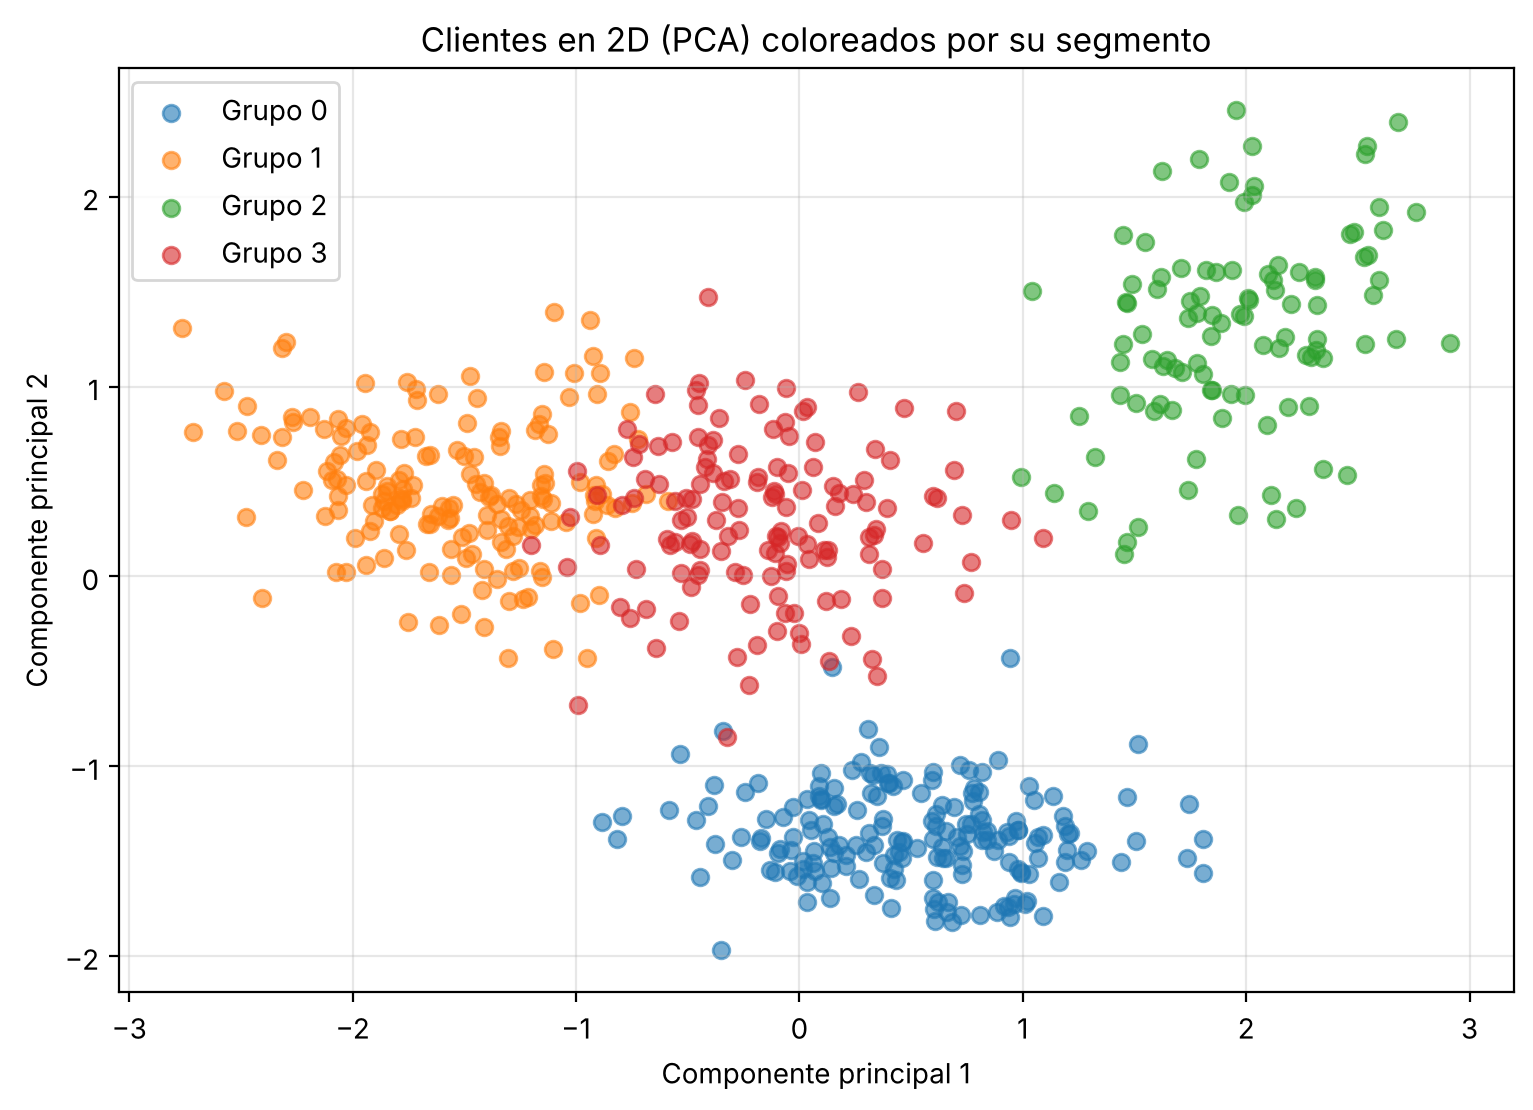

In [16]:
# Visualizamos los clientes en 2D usando PCA, coloreados por su grupo de clustering
plt.figure(figsize=(9, 6))
for g in sorted(clientes["grupo"].unique()):
    mascara = clientes["grupo"] == g
    plt.scatter(componentes[mascara, 0], componentes[mascara, 1], label=f"Grupo {g}", alpha=0.6)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Clientes en 2D (PCA) coloreados por su segmento")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

> ✍️ **23.** En esta gráfica PCA, ¿los grupos de clustering se ven bien separados? PCA + clustering es una combinación muy usada: agrupas en el espacio completo y visualizas en 2D. ¿Te ayudó a "ver" los segmentos?

> ✍️ **24.** PCA combina las variables originales en componentes nuevos. ¿Qué DESVENTAJA tiene esto para la interpretación? (Pista: el "componente 1" ya no es una variable con nombre claro como "edad".)


**Respuesta 23.** Sí. En la gráfica PCA los 4 grupos se ven mejor separados que en ingreso vs gasto: el grupo 2 (premium) queda arriba a la derecha, el grupo 0 (jóvenes) abajo, y los grupos 1 y 3 quedan a la izquierda y al centro, con un traslape pequeño en su frontera. A diferencia de la gráfica anterior, PCA sí incorpora la edad, por eso ahora los grupos 1 y 3 se distinguen. Me ayudó a "ver" los 4 segmentos en una sola imagen.

**Respuesta 24.** Los componentes son **mezclas** de las variables originales (en mi ejecución, el componente 1 ≈ −0.58·edad + 0.37·ingreso + 0.73·gasto, y el componente 2 ≈ 0.57·edad + 0.82·ingreso + 0.04·gasto, con las variables estandarizadas), así que el eje "componente 1" no tiene un significado directo como "edad" o "ingreso". Para explicarlo a negocio hay que revisar los pesos (*loadings*) de cada variable; por eso agrupamos e interpretamos con las variables originales y usamos PCA solo para visualizar.

---
# Cierre — Reflexión


> ✍️ **25.** Resume en tus palabras la diferencia entre aprendizaje supervisado (lo que viste antes) y no supervisado (esta guía). Da un ejemplo de cada uno.

> ✍️ **26.** De las técnicas que aprendiste (clustering, reglas de asociación, PCA), ¿cuál te pareció más útil y en qué problema real la aplicarías?

> ✍️ **27.** El clustering no tiene "respuesta correcta". ¿Cómo sabes entonces si tu agrupamiento es "bueno"? Menciona al menos dos formas de evaluarlo que usaste.

> ✍️ **28.** ¿Qué concepto te costó más entender: el método del codo, el lift de las reglas, o los componentes de PCA? Explica con tus palabras lo que SÍ entendiste de ese concepto.


**Respuesta 25.** En el **supervisado** el modelo aprende a partir de ejemplos con la respuesta conocida (una etiqueta) para predecirla en casos nuevos; por ejemplo, predecir el precio de una casa a partir de sus metros cuadrados y ubicación. En el **no supervisado** no hay respuesta: el algoritmo busca estructura en los datos; por ejemplo, agrupar a estos 600 clientes en 4 segmentos sin saber de antemano cuántos tipos había.

**Respuesta 26.** El **clustering** me pareció lo más útil, porque convierte una tabla de clientes en segmentos accionables. Lo aplicaría, por ejemplo, para segmentar a los usuarios de una app según su uso (frecuencia, tiempo de sesión, funciones usadas) y personalizar notificaciones, o para agrupar registros de tráfico de red y detectar comportamientos anómalos.

**Respuesta 27.** Aunque no hay respuesta correcta, sí se puede evaluar:
1. **Método del codo (inercia):** que los grupos sean compactos y que agregar más grupos ya no mejore mucho.
2. **Coeficiente de silueta:** que cada cliente esté más cerca de su grupo que del grupo vecino (0.466 con k = 4).
3. **Interpretabilidad y visualización:** que cada grupo tenga un perfil claro con sentido de negocio y que se vea separado en la gráfica PCA. También comparar con otro método (el jerárquico dio casi la misma silueta), lo que da confianza en el resultado.

**Respuesta 28.** Lo que más me costó fue **PCA**, porque los componentes no son variables con nombre. Lo que sí entendí: PCA busca las direcciones en las que los datos varían más; la primera dirección captura la mayor parte de la variación (aquí 54.7%), la segunda la mayor parte de lo que queda (35.9%) y es perpendicular a la primera. Proyectar los datos sobre esas direcciones permite verlos en 2D perdiendo poca información (solo 9.4% en este caso).

---
## Cierre y entrega

Aprendiste las técnicas centrales de la minería de datos y el aprendizaje no supervisado: **agrupar** clientes sin etiquetas (K-means, jerárquico, DBSCAN), **evaluar** cuántos grupos usar (codo y silueta), **descubrir** qué productos van juntos (Apriori) y **resumir** muchas variables para visualizarlas (PCA). Sobre todo, aprendiste a **interpretar** los patrones que las máquinas encuentran, que es lo que les da valor.

### Entrega en Google Classroom

1. Verifica que **todas las celdas corran sin error** en VS Code.
2. Confirma que respondiste las **28 preguntas** y los **3 retos**.
3. Sube tu notebook (o súbelo a GitHub y comparte el enlace) en Classroom.

### Rúbrica

| Criterio | Puntos |
|---|---|
| Todas las celdas se ejecutan correctamente | 15 |
| Retos de código resueltos (3) | 20 |
| Respuestas a las 28 preguntas | 40 |
| Interpretación de clusters y reglas | 25 |
| **Total** | **100** |

---
*Universidad de Especialidades UNE · Plantel Centro · Optativa III: Ciencia de Datos*
*Datasets: clientes.csv y transacciones.csv*
